In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import datetime as dt


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
sns.set(style='whitegrid')
plt.rcParams['figure.figsize'] = (10,6)

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving archive (5).zip to archive (5).zip


In [ ]:
import zipfile
import io

zip_ref = zipfile.ZipFile(io.BytesIO(uploaded['archive (5).zip']), 'r')
zip_ref.extractall('/content/')
zip_ref.close()

In [ ]:
import pandas as pd
df = pd.read_excel('/content/Online Retail.xlsx')

In [ ]:
df.head()
df.sample()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [ ]:
from google.colab import data_table
data_table.enable_dataframe_formatter()
df

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France


In [ ]:
# Check missing values
print("\nMissing values in each column:")
print(df.isnull().sum())


Missing values in each column:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [ ]:
# Remove rows with missing CustomerID
df = df.dropna(subset=['CustomerID'])

In [ ]:
df.shape

(406829, 8)

In [ ]:
# Filter positive quantities and unit prices
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]

In [ ]:
df.shape

(397884, 8)

In [ ]:
# Convert InvoiceDate to datetime
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

In [ ]:
df['TotalPrice'] = df['Quantity'] * df['UnitPrice']

In [ ]:
df

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
...,...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France,10.20
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France,12.60
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60


In [ ]:
print("\n✅ Data cleaned successfully!")
print("New dataset shape:", df.shape)


✅ Data cleaned successfully!
New dataset shape: (397884, 9)


In [ ]:
snapshot_date = df['InvoiceDate'].max() + dt.timedelta(days=1)

rfm = df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (snapshot_date - x.max()).days,
    'InvoiceNo': 'count',
    'TotalPrice': 'sum'
})

rfm.rename(columns={'InvoiceDate': 'Recency',
                    'InvoiceNo': 'Frequency',
                    'TotalPrice': 'Monetary'}, inplace=True)

display(rfm.head())

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,182,4310.00
12348.0,75,31,1797.24
12349.0,19,73,1757.55
12350.0,310,17,334.40


In [ ]:
print("\nDescriptive statistics:")
display(rfm.describe())


Descriptive statistics:


,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.536422,91.720609,2054.266460
std,100.014169,228.785094,8989.230441
min,1.000000,1.000000,3.750000
25%,18.000000,17.000000,307.415000
50%,51.000000,41.000000,674.485000
75%,142.000000,100.000000,1661.740000
max,374.000000,7847.000000,280206.020000


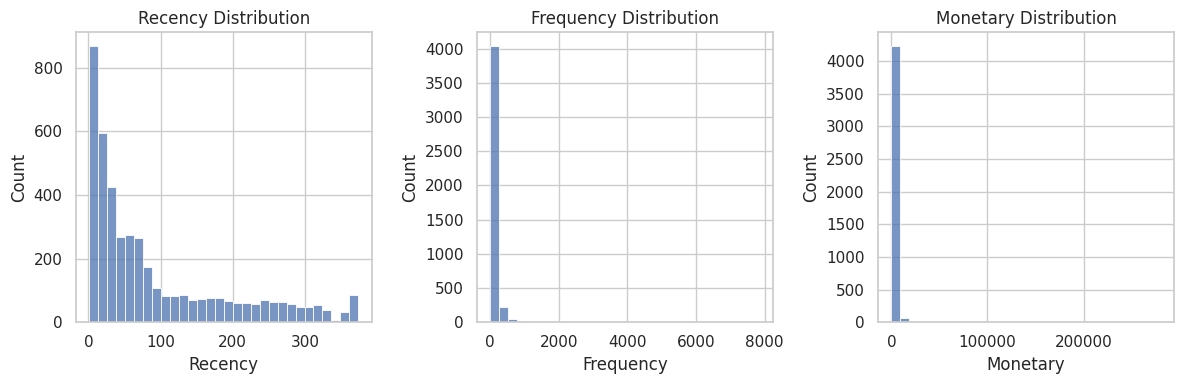

In [ ]:
# --- Distribution plots
plt.figure(figsize=(12,4))
plt.subplot(1,3,1)
sns.histplot(rfm['Recency'], bins=30)
plt.title('Recency Distribution')

plt.subplot(1,3,2)
sns.histplot(rfm['Frequency'], bins=30)
plt.title('Frequency Distribution')

plt.subplot(1,3,3)
sns.histplot(rfm['Monetary'], bins=30)
plt.title('Monetary Distribution')
plt.tight_layout()
plt.show()

In [ ]:
# --- Top 10 High-Value Customers
top_customers = rfm.sort_values('Monetary', ascending=False).head(10)
print("\nTop 10 high-value customers:")
display(top_customers)


Top 10 high-value customers:


,Recency,Frequency,Monetary
CustomerID,,,
14646.0,2,2076,280206.02
18102.0,1,431,259657.30
17450.0,8,337,194550.79
16446.0,1,3,168472.50
14911.0,1,5675,143825.06
12415.0,24,714,124914.53
14156.0,10,1400,117379.63
17511.0,3,963,91062.38
16029.0,39,242,81024.84


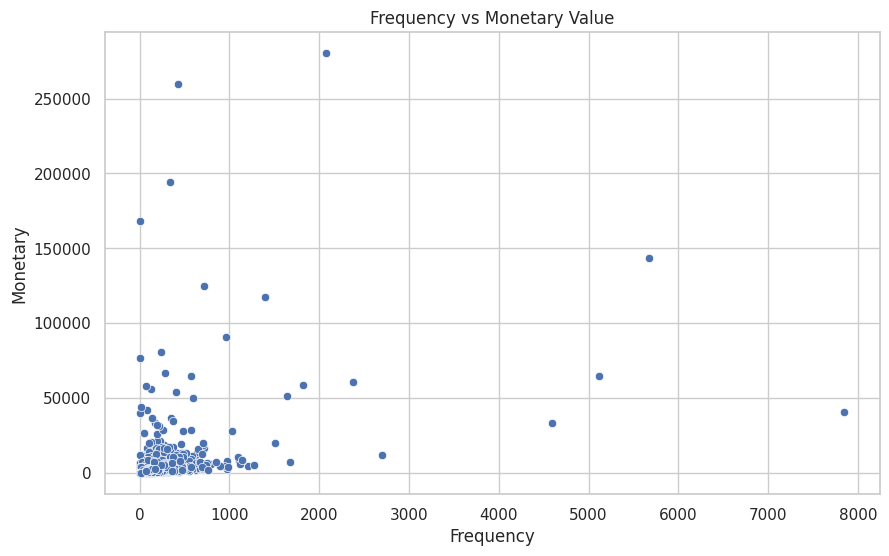

In [ ]:
# --- Relationship: Frequency vs Monetary
sns.scatterplot(x='Frequency', y='Monetary', data=rfm)
plt.title("Frequency vs Monetary Value")
plt.show()

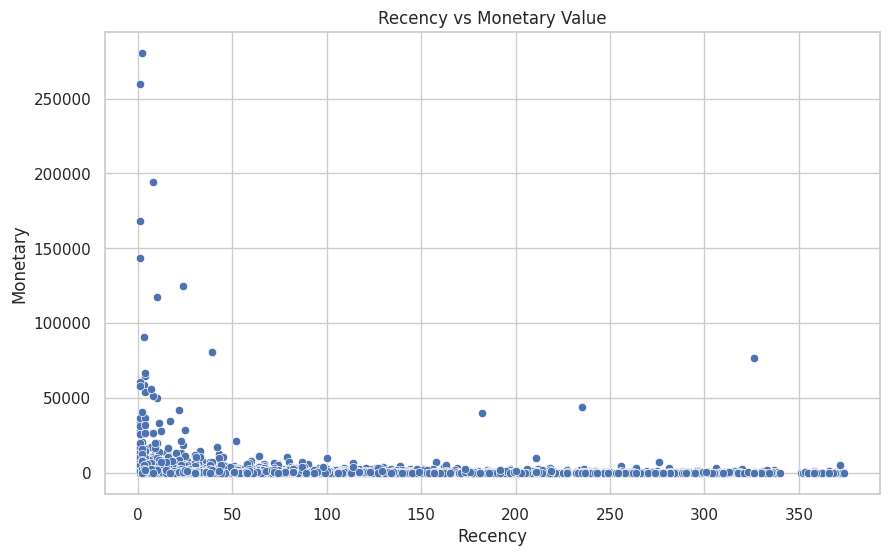

In [ ]:
# --- Relationship: Recency vs Monetary
sns.scatterplot(x='Recency', y='Monetary', data=rfm)
plt.title("Recency vs Monetary Value")
plt.show()

In [ ]:
print("""
✔ Dataset loaded successfully from Kaggle
✔ Cleaned missing, invalid, and cancelled data
✔ Engineered RFM features
✔ Performed EDA with distributions

Next Steps:
➡ Apply scaling and K-Means clustering
➡ Analyze and visualize customer segments
""")


✔ Dataset loaded successfully from Kaggle
✔ Cleaned missing, invalid, and cancelled data
✔ Engineered RFM features
✔ Performed EDA with distributions

Next Steps:
➡ Apply scaling and K-Means clustering
➡ Analyze and visualize customer segments



In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm)

rfm_scaled[:5]

array([[ 2.33457414, -0.3965777 ,  8.35866818],
       [-0.90534032,  0.39464896,  0.25096626],
       [-0.17535959, -0.26543516, -0.02859601],
       [-0.73534481, -0.08183561, -0.0330118 ],
       [ 2.17457836, -0.32663501, -0.19134727]])

In [ ]:
from sklearn.preprocessing import StandardScaler
rfm_log = np.log1p(rfm)  # log transform to reduce skew
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)


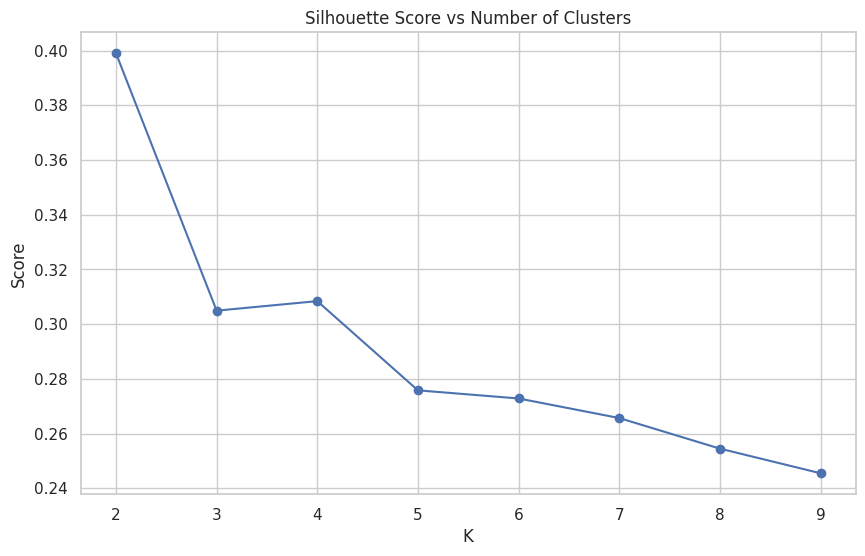

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

scores = []
for k in range(2, 10):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(rfm_scaled)
    scores.append(silhouette_score(rfm_scaled, kmeans.labels_))

plt.plot(range(2,10), scores, marker='o')
plt.title("Silhouette Score vs Number of Clusters")
plt.xlabel("K")
plt.ylabel("Score")
plt.show()


In [ ]:
kmeans = KMeans(n_clusters=4, random_state=42)
rfm['Cluster'] = kmeans.fit_predict(rfm_scaled)


In [ ]:
import plotly.express as px
fig = px.scatter_3d(rfm, x='Recency', y='Frequency', z='Monetary',
                    color='Cluster', title='RFM Clusters')
fig.show()


In [ ]:
cluster_summary = rfm.groupby("Cluster").mean()
cluster_summary


,Recency,Frequency,Monetary
Cluster,,,
0,20.414352,37.123843,588.002535
1,94.341660,80.112812,1515.635587
2,12.845538,281.406178,6996.487941
3,187.991170,15.040471,299.881892


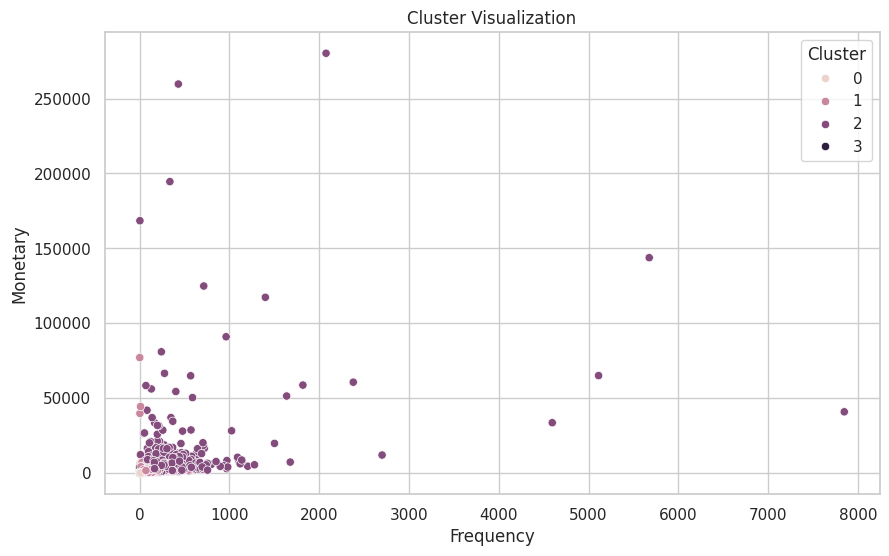

In [ ]:
sns.scatterplot(data=rfm, x="Frequency", y="Monetary", hue="Cluster")
plt.title("Cluster Visualization")
plt.show()
